# Physical-metric calculation pipeline

**Analytical question:** Measure movement and physical effort.

**Stages in this notebook:** Smooth positions; velocity; acceleration; distance integration; intensity bands; efforts; crossing times; sample peaks.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## Smooth and differentiate within continuous segments
Compute velocity from coordinate gradients and actual timestamps. Split at missing data, gaps and periods. Gaussian smoothing here is retrospective and symmetric: live prediction needs a causal alternative or latency allowance. Exclude filter boundaries. [DataBallPy](https://databallpy.readthedocs.io/en/main/), [SkillCorner acceleration definitions](https://skillcorner.com/articles/new-feature-explosive-accelerations) and [SkillCorner peak-speed definitions](https://skillcorner.com/articles/skillcorner-releases-new-peak-velocity-metric) provide the methodological context; our estimates do not recreate proprietary processing.

In [4]:
from scipy.ndimage import gaussian_filter1d
motion=tracking.copy()
motion[['vx','vy','speed_kmh','accel']]=np.nan
for _,g in motion.groupby(['player_id','period_id']):
    valid=g[['x','y']].notna().all(axis=1)
    splits=(~valid|~valid.shift(fill_value=False)|g.frame_id.diff().ne(1)|g.seconds.diff().le(0)).cumsum()
    for _,s in g[valid].groupby(splits[valid]):
        if len(s)<20:continue
        xy=gaussian_filter1d(s[['x','y']].to_numpy(),sigma=1.5,axis=0,mode='nearest')
        v=np.gradient(xy,s.seconds.to_numpy(),axis=0);speed=np.linalg.norm(v,axis=1)
        acceleration=np.gradient(speed,s.seconds.to_numpy())
        v[:5]=np.nan;v[-5:]=np.nan;speed[:5]=np.nan;speed[-5:]=np.nan
        acceleration[:6]=np.nan;acceleration[-6:]=np.nan
        motion.loc[s.index,['vx','vy']]=v;motion.loc[s.index,'speed_kmh']=speed*3.6;motion.loc[s.index,'accel']=acceleration
display(motion[['player_id','frame_id','vx','vy','speed_kmh','accel']].dropna().head())

,player_id,frame_id,vx,vy,speed_kmh,accel
67689,11897,46,-0.247765,0.174801,1.091594,0.606738
67690,11897,47,-0.290122,0.221082,1.313129,0.610326
67691,11897,48,-0.324011,0.275472,1.531029,0.607658
67692,11897,49,-0.350501,0.337086,1.750643,0.646995
67693,11897,50,-0.378850,0.405152,1.996865,0.738426


### Intermediate steps: Inspect smoothing and numerical differentiation

Boundary values in this diagnostic are shown to explain the filter. The metric calculation above excludes them.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `smooth_coordinates`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [5]:
def smooth_coordinates(xy,sigma=1.5):
    return gaussian_filter1d(np.asarray(xy),sigma=sigma,axis=0,mode='nearest')

#### Helper: `differentiate_coordinates`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [6]:
def differentiate_coordinates(xy,time):
    return np.gradient(np.asarray(xy),np.asarray(time),axis=0)

,time,raw_x,smooth_x,raw_vx,smooth_vx
0,462.7,-30.86,-30.819590,0.70,0.448439
1,462.8,-30.79,-30.774746,0.70,0.530296
2,462.9,-30.72,-30.713531,0.70,0.666926
3,463.0,-30.65,-30.641361,0.75,0.760147
4,463.1,-30.57,-30.561501,0.85,0.831427
5,463.2,-30.48,-30.475075,0.90,0.894987
6,463.3,-30.39,-30.382504,0.95,0.957296
7,463.4,-30.29,-30.283616,1.00,1.023382
8,463.5,-30.19,-30.177828,1.10,1.092181
9,463.6,-30.07,-30.065180,1.20,1.155095


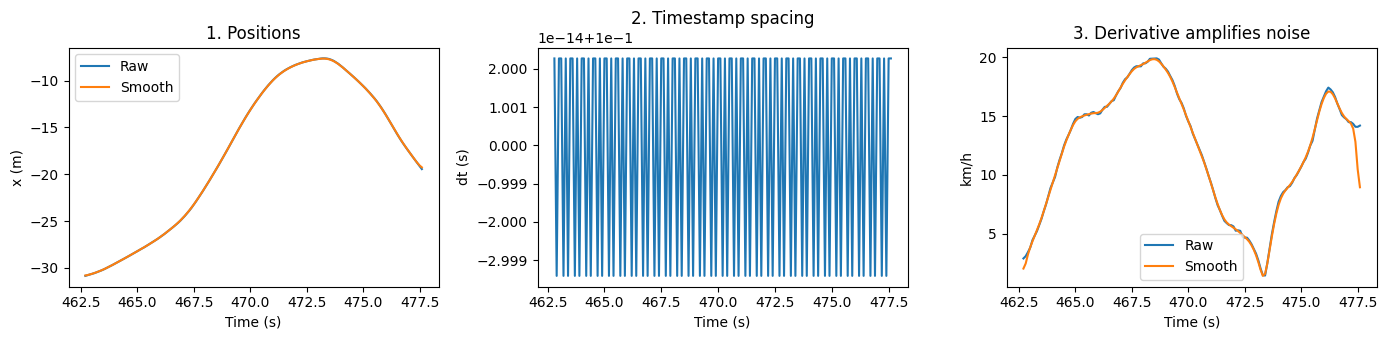

In [7]:
player=motion.groupby('player_id').speed_kmh.max().idxmax()
g=tracking[tracking.player_id.eq(player)].dropna(subset=['x','y']).sort_values('frame_id')
breaks=(g.frame_id.diff().ne(1)|g.period_id.ne(g.period_id.shift())).cumsum()
segment=max((s for _,s in g.groupby(breaks)),key=len).head(150)
xy=segment[['x','y']].to_numpy()
smoothed=smooth_coordinates(xy)
t=segment.seconds.to_numpy()
raw_velocity=differentiate_coordinates(xy,t)
smooth_velocity=differentiate_coordinates(smoothed,t)
display(pd.DataFrame({'time':t,'raw_x':xy[:,0],'smooth_x':smoothed[:,0],'raw_vx':raw_velocity[:,0],'smooth_vx':smooth_velocity[:,0]}).head(10))
fig,axs=plt.subplots(1,3,figsize=(14,3.5))
axs[0].plot(t,xy[:,0],label='Raw')
axs[0].plot(t,smoothed[:,0],label='Smooth')
axs[0].set(title='1. Positions',ylabel='x (m)')
axs[0].legend()
axs[1].plot(t,np.diff(t,prepend=np.nan))
axs[1].set(title='2. Timestamp spacing',ylabel='dt (s)')
axs[2].plot(t,np.linalg.norm(raw_velocity,axis=1)*3.6,label='Raw')
axs[2].plot(t,np.linalg.norm(smooth_velocity,axis=1)*3.6,label='Smooth')
axs[2].set(title='3. Derivative amplifies noise',ylabel='km/h')
axs[2].legend()
for ax in axs:ax.set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

## Distance, intensity bands and coverage
Integrate trapezoidally over valid neighboring speed estimates. Allocate intervals to intensity bands by mean interval speed. This differs slightly from frame-rectangle conventions; disclose the convention. The men's HSR and sprint thresholds here are 20 and 25 km/h. Report valid exposure and avoid scaling a partial sample into a full match.

,player_id,valid_s,distance_m,HSR_m,sprint_m,coverage,sample_peak_kmh
15,795530,599.0,1827.779733,127.104950,5.918825,0.973509,27.568458
20,966112,600.1,1782.537938,112.206502,0.000000,0.975297,24.897186
1,287934,599.1,1734.763138,133.898882,68.533104,0.973671,28.348777
12,560986,598.4,1673.156061,194.571831,59.046084,0.972534,29.551199
7,51694,596.7,1663.598835,89.350435,8.536913,0.969771,26.061642
13,560987,600.3,1662.790754,166.090654,22.804554,0.975622,29.110785
9,560983,601.5,1589.803595,148.280257,95.723360,0.977572,36.498076
8,560882,596.4,1589.280732,99.438639,19.340130,0.969283,26.348442
17,797298,599.1,1578.731245,149.828188,31.745373,0.973671,28.210902
4,51002,601.5,1568.436447,164.024403,0.000000,0.977572,25.000118


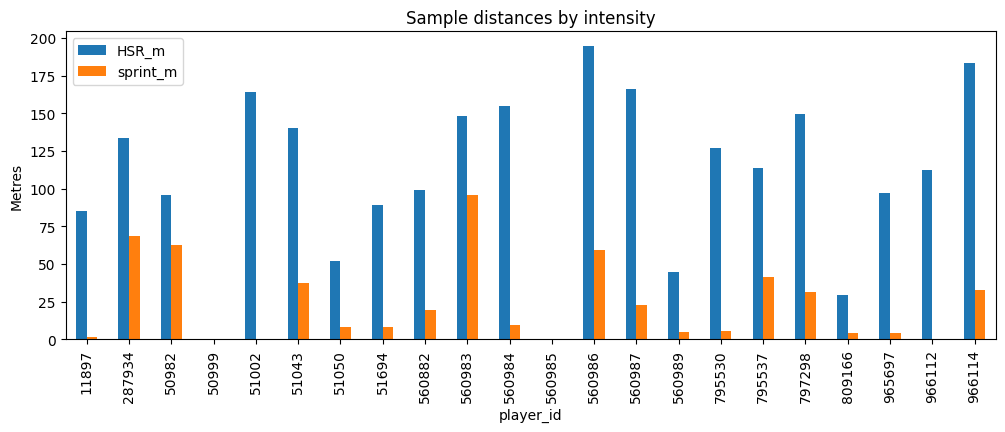

In [8]:
summaries=[]
for pid,g in motion.groupby('player_id'):
    g=g.sort_values(['period_id','frame_id']);dt=g.seconds.diff()
    valid=g.period_id.eq(g.period_id.shift())&g.frame_id.diff().eq(1)&dt.gt(0)&g.speed_kmh.notna()&g.speed_kmh.shift().notna()
    interval_speed=(g.speed_kmh+g.speed_kmh.shift())/2
    distance=interval_speed/3.6*dt
    summaries.append(dict(player_id=pid,valid_s=dt.where(valid).sum(),distance_m=distance.where(valid).sum(),HSR_m=distance.where(valid&interval_speed.ge(20)&interval_speed.lt(25)).sum(),sprint_m=distance.where(valid&interval_speed.ge(25)).sum(),coverage=valid.mean(),sample_peak_kmh=g.speed_kmh.max()))
summary=pd.DataFrame(summaries)
display(summary.sort_values('distance_m',ascending=False).head(10))
summary.set_index('player_id')[['HSR_m','sprint_m']].plot.bar(figsize=(12,4),title='Sample distances by intensity')
plt.ylabel('Metres')
plt.show()

### Intermediate steps: Inspect interval integration before summing metres

Missing derivatives contribute no measured distance and must still reduce reported coverage. Band boundaries use interval mean speed.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `interval_workload`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [9]:
def interval_workload(g):
    result=g.sort_values(['period_id','frame_id']).copy()
    result['dt']=result.seconds.diff();result['mean_kmh']=(result.speed_kmh+result.speed_kmh.shift())/2
    valid=result.period_id.eq(result.period_id.shift())&result.frame_id.diff().eq(1)&result.dt.gt(0)&result.speed_kmh.notna()&result.speed_kmh.shift().notna()
    result['metres']=(result.mean_kmh/3.6*result.dt).where(valid)
    result['cumulative_m']=result.metres.fillna(0).cumsum()
    result['band']=np.select([result.mean_kmh.ge(25),result.mean_kmh.ge(20)],['sprint','HSR'],default='below HSR')
    return result

,frame_id,dt,mean_kmh,band,metres,cumulative_m
123066,46,0.1,1.095098,below HSR,0.030419,0.030419
123067,47,0.1,1.020167,below HSR,0.028338,0.058757
123068,48,0.1,0.872024,below HSR,0.024223,0.082980
123069,49,0.1,0.631472,below HSR,0.017541,0.100521
123070,50,0.1,0.296680,below HSR,0.008241,0.108762
123071,51,0.1,0.262038,below HSR,0.007279,0.116041
123072,52,0.1,0.732313,below HSR,0.020342,0.136383
123073,53,0.1,1.416043,below HSR,0.039335,0.175718
123074,54,0.1,2.195339,below HSR,0.060982,0.236699
123075,55,0.1,3.057082,below HSR,0.084919,0.321618


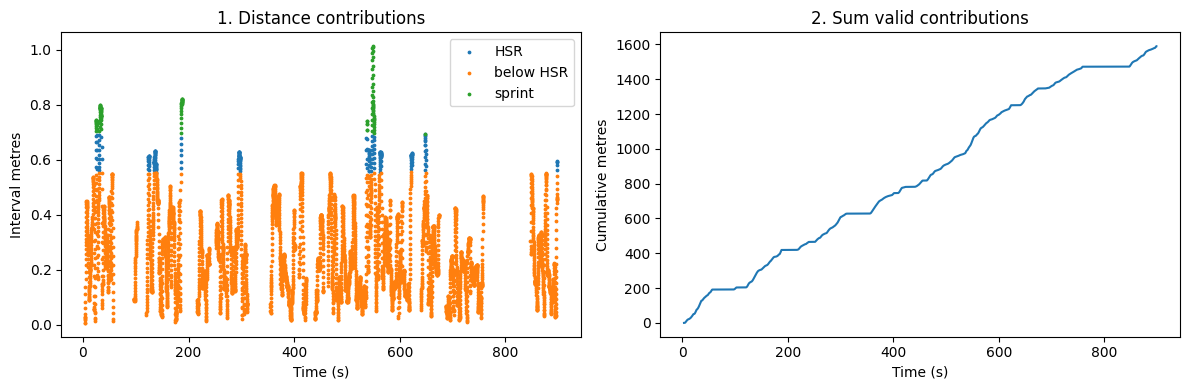

In [10]:
intervals=interval_workload(motion[motion.player_id.eq(player)])
display(intervals[['frame_id','dt','mean_kmh','band','metres','cumulative_m']].dropna().head(12))
fig,axs=plt.subplots(1,2,figsize=(12,4))
for band,g in intervals.groupby('band'):axs[0].scatter(g.seconds,g.metres,s=3,label=band)
axs[0].set(title='1. Distance contributions',xlabel='Time (s)',ylabel='Interval metres')
axs[0].legend()
axs[1].plot(intervals.seconds,intervals.cumulative_m)
axs[1].set(title='2. Sum valid contributions',xlabel='Time (s)',ylabel='Cumulative metres')
plt.tight_layout()
plt.show()

#### Helper: `band_contributions`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [11]:
def band_contributions(g):
    g=g.sort_values(['period_id','frame_id']).copy();dt=g.seconds.diff();v=(g.speed_kmh+g.speed_kmh.shift())/2
    valid=g.frame_id.diff().eq(1)&g.period_id.eq(g.period_id.shift())&dt.gt(0)&g.speed_kmh.notna()&g.speed_kmh.shift().notna()
    g['mean_kmh']=v;g['distance']=(v/3.6*dt).where(valid)
    g['HSR']=g.distance.where(v.ge(20)&v.lt(25),0);g['sprint']=g.distance.where(v.ge(25),0);return g

,seconds,mean_kmh,distance,HSR,sprint
123066,3.6,1.095098,0.030419,0.0,0.0
123067,3.7,1.020167,0.028338,0.0,0.0
123068,3.8,0.872024,0.024223,0.0,0.0
123069,3.9,0.631472,0.017541,0.0,0.0
123070,4.0,0.296680,0.008241,0.0,0.0
123071,4.1,0.262038,0.007279,0.0,0.0
123072,4.2,0.732313,0.020342,0.0,0.0
123073,4.3,1.416043,0.039335,0.0,0.0
123074,4.4,2.195339,0.060982,0.0,0.0
123075,4.5,3.057082,0.084919,0.0,0.0


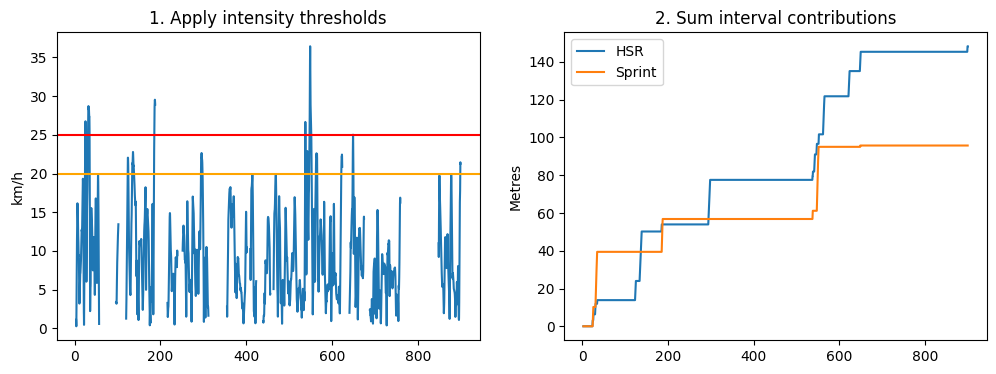

In [12]:
player=motion.groupby('player_id').speed_kmh.max().idxmax()
contributions=band_contributions(motion[motion.player_id.eq(player)])
display(contributions[['seconds','mean_kmh','distance','HSR','sprint']].dropna().head(10))
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(contributions.seconds,contributions.mean_kmh)
axs[0].axhline(20,c='orange')
axs[0].axhline(25,c='red')
axs[0].set(title='1. Apply intensity thresholds',ylabel='km/h')
axs[1].plot(contributions.seconds,contributions.HSR.fillna(0).cumsum(),label='HSR')
axs[1].plot(contributions.seconds,contributions.sprint.fillna(0).cumsum(),label='Sprint')
axs[1].set(title='2. Sum interval contributions',ylabel='Metres')
axs[1].legend()
plt.show()

## Sprint efforts and signed acceleration
Consecutive speed at or above 25 km/h for at least one second defines an effort **in this notebook**. No short-gap merging. Signed scalar acceleration measures speeding up/braking, while vector acceleration also responds to direction changes.

,player_id,start_s,duration_s,peak_kmh
0,287934,133.4,3.5,27.431501
1,287934,364.3,4.0,28.348777
2,287934,673.0,1.1,27.390025
3,50982,134.0,4.8,29.822522
4,50982,186.1,1.2,26.187768


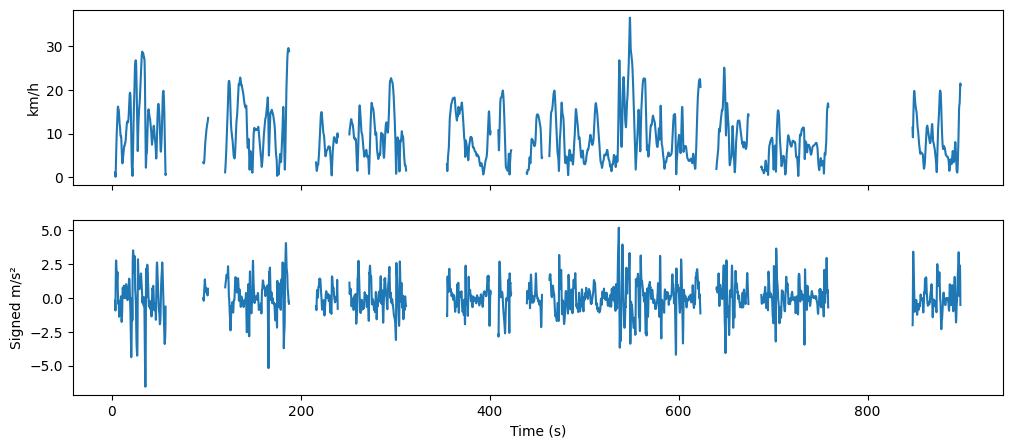

In [13]:
effort_rows=[]
for pid,g in motion.groupby('player_id'):
    g=g.sort_values(['period_id','frame_id']);active=g.speed_kmh.ge(25)
    segment=(active.ne(active.shift(fill_value=False))|g.frame_id.diff().ne(1)|g.period_id.ne(g.period_id.shift())).cumsum()
    for _,s in g[active].groupby(segment[active]):
        duration=s.seconds.iloc[-1]-s.seconds.iloc[0]+.1
        if duration>=1:effort_rows.append(dict(player_id=pid,start_s=s.seconds.iloc[0],duration_s=duration,peak_kmh=s.speed_kmh.max()))
display(pd.DataFrame(effort_rows,columns=['player_id','start_s','duration_s','peak_kmh']).head())
pid=summary.sort_values('sample_peak_kmh',ascending=False).player_id.iloc[0]
g=motion[motion.player_id.eq(pid)]
fig,axs=plt.subplots(2,1,figsize=(12,5),sharex=True)
axs[0].plot(g.seconds,g.speed_kmh)
axs[0].set_ylabel('km/h')
axs[1].plot(g.seconds,g.accel)
axs[1].set(xlabel='Time (s)',ylabel='Signed m/s²')
plt.show()

#### Helper: `acceleration_components`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [14]:
def acceleration_components(g):
    g=g.sort_values('frame_id').copy();time=g.seconds.to_numpy()
    v=g[['vx','vy']].to_numpy();vector=np.gradient(v,time,axis=0)
    magnitude=np.linalg.norm(vector,axis=1)
    return pd.DataFrame({'time':time,'scalar_accel':g.accel.to_numpy(),'vector_magnitude':magnitude})

,time,scalar_accel,vector_magnitude
0,463.3,1.346041,1.414835
1,463.4,1.440941,1.473997
2,463.5,1.555566,1.602213
3,463.6,1.657018,1.738788
4,463.7,1.719011,1.841087


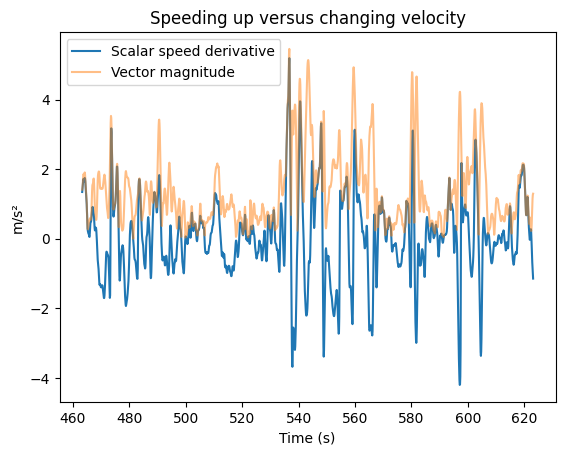

In [15]:
g=motion[motion.player_id.eq(motion.groupby('player_id').speed_kmh.max().idxmax())].dropna(subset=['vx','vy','accel'])
segments=(g.frame_id.diff().ne(1)|g.period_id.ne(g.period_id.shift())).cumsum()
g=max((s for _,s in g.groupby(segments)),key=len)
diagnostic=acceleration_components(g)
display(diagnostic.head())
plt.plot(diagnostic.time,diagnostic.scalar_accel,label='Scalar speed derivative')
plt.plot(diagnostic.time,diagnostic.vector_magnitude,label='Vector magnitude',alpha=.5)
plt.legend()
plt.xlabel('Time (s)')
plt.ylabel('m/s²')
plt.title('Speeding up versus changing velocity')
plt.show()

## Time from 9 to 20 / 25 km/h
Find consecutive rising-speed episodes, interpolate threshold crossings, and inspect durations. SkillCorner reports these metrics within **qualifying explosive accelerations** with additional production rules; the crossings below are not official Time to HSR / Time to Sprint. PSV-99 uses its specified activity population and cannot be replaced by an all-frame 99th percentile. Our sample peak is also distinct from validated production Peak Velocity.

#### Helper: `crossing_time`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [16]:
def crossing_time(t,v,threshold):
    hits=np.flatnonzero((v[:-1]<threshold)&(v[1:]>=threshold))
    if not len(hits):return np.nan
    i=hits[0];return t[i]+(threshold-v[i])/(v[i+1]-v[i])*(t[i+1]-t[i])

In [17]:
crossings=[]
for pid,g in motion.groupby('player_id'):
    g=g.sort_values(['period_id','frame_id']);rising=g.accel.gt(0)&g.speed_kmh.notna()
    segment=(rising.ne(rising.shift(fill_value=False))|g.frame_id.diff().ne(1)|g.period_id.ne(g.period_id.shift())).cumsum()
    for _,s in g[rising].groupby(segment[rising]):
        if len(s)<3:continue
        t=s.seconds.to_numpy();v=s.speed_kmh.to_numpy();t9=crossing_time(t,v,9)
        for threshold in [20]:
            end=crossing_time(t,v,threshold)
            if np.isfinite(t9+end) and end>t9:crossings.append(dict(player_id=pid,target_kmh=threshold,seconds=end-t9))
display(pd.DataFrame(crossings,columns=['player_id','target_kmh','seconds']).head(12))
assert np.isclose(crossing_time(np.array([0,1]),np.array([0,20]),9),.45)

,player_id,target_kmh,seconds
0,11897,20,1.863908
1,11897,20,1.233406
2,11897,20,1.087799
3,11897,20,1.199481
4,287934,20,1.642657
5,287934,20,0.827738
6,287934,20,2.127895
7,287934,20,1.991966
8,287934,20,1.737400
9,50982,20,1.821617


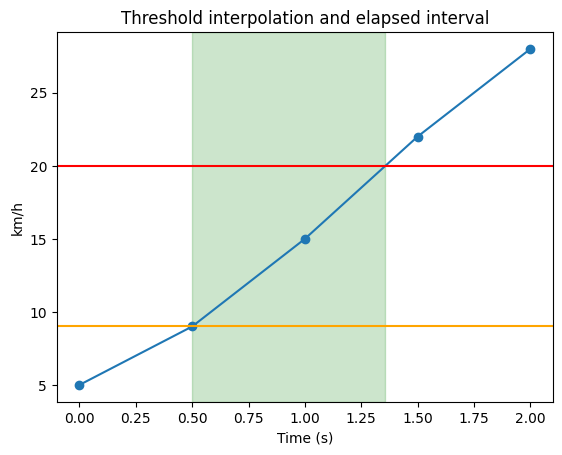

Synthetic crossing interval: 0.8571428571428572


In [18]:
t=np.array([0.,.5,1.,1.5,2.])
v=np.array([5.,9.,15.,22.,28.])
t9=crossing_time(t,v,9)
end=crossing_time(t,v,20)
plt.plot(t,v,'o-')
plt.axhline(9,c='orange')
plt.axhline(20,c='red')
plt.axvspan(t9,end,alpha=.2,color='green')
plt.xlabel('Time (s)')
plt.ylabel('km/h')
plt.title('Threshold interpolation and elapsed interval')
plt.show()
print('Synthetic crossing interval:',end-t9)

In [19]:
crossings=[]
for pid,g in motion.groupby('player_id'):
    g=g.sort_values(['period_id','frame_id']);rising=g.accel.gt(0)&g.speed_kmh.notna()
    segment=(rising.ne(rising.shift(fill_value=False))|g.frame_id.diff().ne(1)|g.period_id.ne(g.period_id.shift())).cumsum()
    for _,s in g[rising].groupby(segment[rising]):
        if len(s)<3:continue
        t=s.seconds.to_numpy();v=s.speed_kmh.to_numpy();t9=crossing_time(t,v,9)
        for threshold in [25]:
            end=crossing_time(t,v,threshold)
            if np.isfinite(t9+end) and end>t9:crossings.append(dict(player_id=pid,target_kmh=threshold,seconds=end-t9))
display(pd.DataFrame(crossings,columns=['player_id','target_kmh','seconds']).head(12))
assert np.isclose(crossing_time(np.array([0,1]),np.array([0,20]),9),.45)

,player_id,target_kmh,seconds
0,287934,25,2.927325
1,287934,25,2.171694
2,50982,25,2.894960
3,50982,25,2.323838
4,50982,25,3.174300
5,51043,25,3.713316
6,51043,25,1.002873
7,51043,25,2.985500
8,51050,25,3.324247
9,51694,25,2.203762


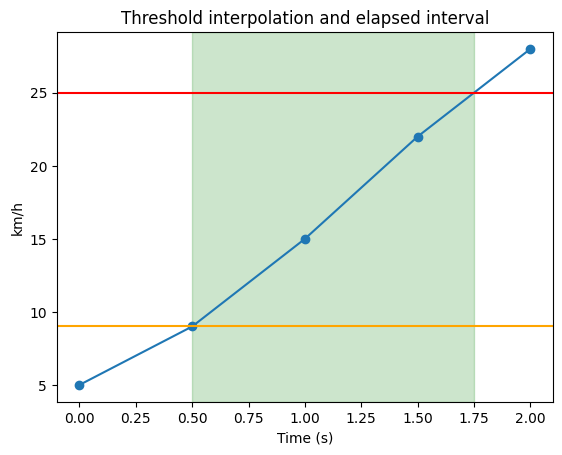

Synthetic crossing interval: 1.25


In [20]:
t=np.array([0.,.5,1.,1.5,2.])
v=np.array([5.,9.,15.,22.,28.])
t9=crossing_time(t,v,9)
end=crossing_time(t,v,25)
plt.plot(t,v,'o-')
plt.axhline(9,c='orange')
plt.axhline(25,c='red')
plt.axvspan(t9,end,alpha=.2,color='green')
plt.xlabel('Time (s)')
plt.ylabel('km/h')
plt.title('Threshold interpolation and elapsed interval')
plt.show()
print('Synthetic crossing interval:',end-t9)

#### Helper: `inspect_peak`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [21]:
def inspect_peak(g):
    peak=g.loc[g.speed_kmh.idxmax()];window=g[g.frame_id.between(peak.frame_id-30,peak.frame_id+30)&g.period_id.eq(peak.period_id)]
    return peak,window

,frame_id,seconds,speed_kmh,is_detected
126839,5465,545.5,17.499423,False
126840,5466,545.6,17.604080,False
126841,5467,545.7,17.775706,False
126842,5468,545.8,18.046055,False
126843,5469,545.9,18.416395,False


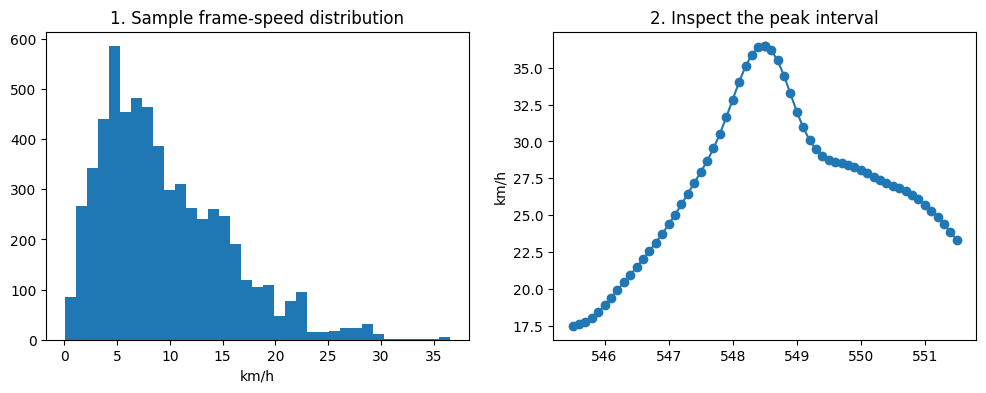

Smoothed sample maximum only: 36.49807558145191
This is not production Peak Velocity or PSV-99; PSV-99 requires its specified activity population.


In [22]:
player=motion.groupby('player_id').speed_kmh.max().idxmax()
peak,window=inspect_peak(motion[motion.player_id.eq(player)])
display(window[['frame_id','seconds','speed_kmh','is_detected']].head())
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].hist(motion[motion.player_id.eq(player)].speed_kmh.dropna(),bins=35)
axs[0].set(title='1. Sample frame-speed distribution',xlabel='km/h')
axs[1].plot(window.seconds,window.speed_kmh,'o-')
axs[1].scatter(peak.seconds,peak.speed_kmh,c='red')
axs[1].set(title='2. Inspect the peak interval',ylabel='km/h')
plt.show()
print('Smoothed sample maximum only:',peak.speed_kmh)
print('This is not production Peak Velocity or PSV-99; PSV-99 requires its specified activity population.')

## Review the full method
Trace each final quantity back through its helper functions, intermediate arrays and visual diagnostics. Change one modeling assumption and rerun its dependent cells. Review coverage, attack direction, phase context and evaluation design before interpreting real sample results. Keep synthetic demonstrations and proxy quantities separate from trained or production model outputs.

This notebook is deliberately self-contained. Shared *concepts* such as smoothing or graph normalization are repeated inline where needed; another notebook never needs to run first.
